# Imports

In [2]:
import os, sys
sys.path.append("D:\\DATA\\ETL_PIC\\simulation\\")
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rc_file('D:\\DATA\\ETL_PIC\\matplotlibrc.txt')
import pandas as pd
from tqdm import tqdm

import rsoft_lib as rlib
from rsoft_lib.device_setup import SIM, DESIGN_WAVELENGTH, WIDTH, device_paths, export_device

# Design device

For unbalanced MZIs, we generate delay arms with a bump made from two circular s-bends extended along the z-direction with a straight between them. We use the ```delay_arm()``` function to generate the delay arm in terms of ```z_length``` (the length along the z-axis), ```deltaL``` (path length difference between the delay arm and a straight of equivalent length along the z-axis), and ```R``` (bend radius of the s-bends). 

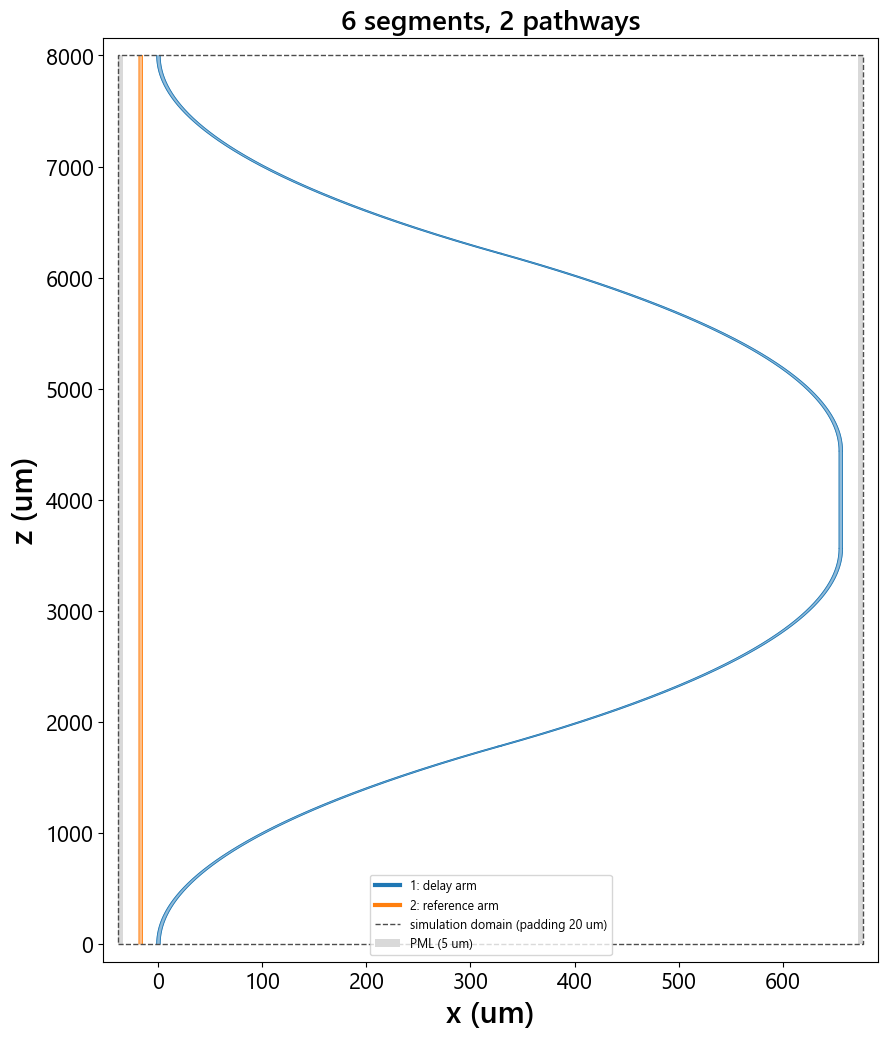

P-05a_UnbalancedMZI: delay arm - reference arm = 160.000000 μm (design 160 μm)
Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-05_UnbalancedMZI\P-05a_UnbalancedMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-05_UnbalancedMZI\P-05a_UnbalancedMZI.gds; 80000 propagation steps per wavelength


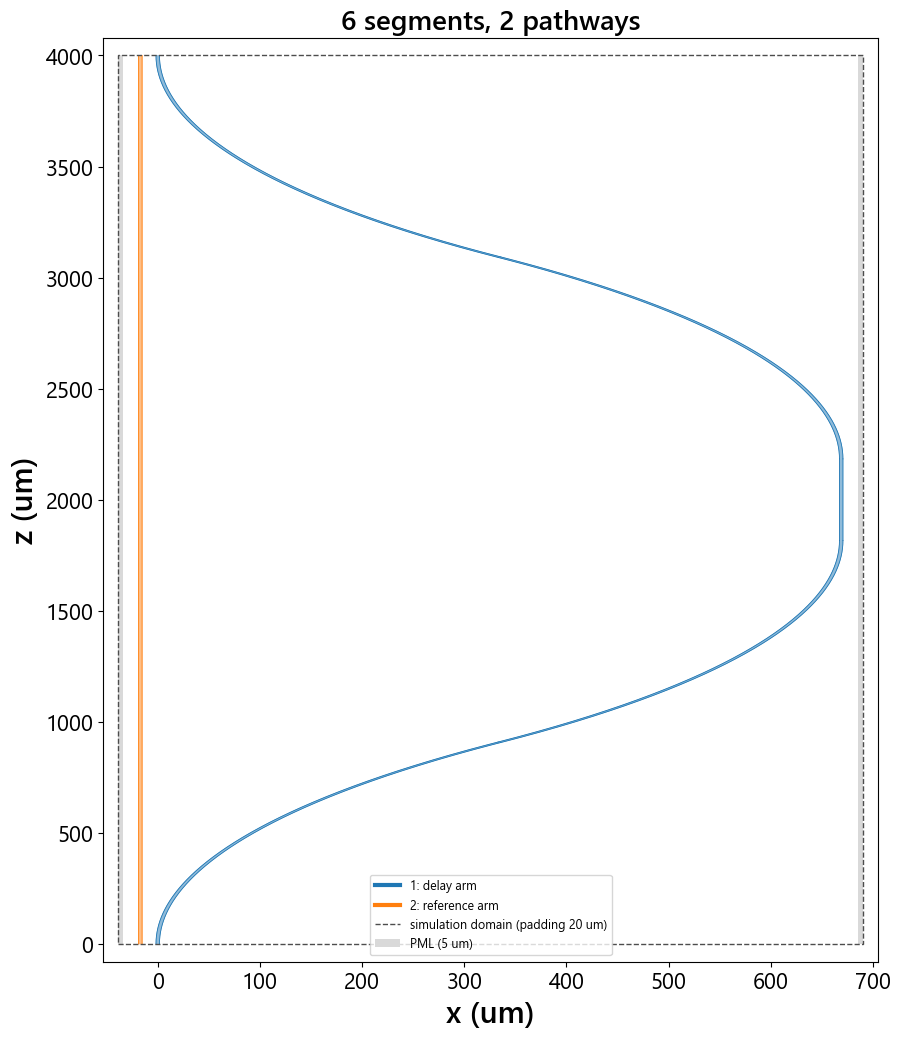

P-05b_UnbalancedMZI: delay arm - reference arm = 320.000000 μm (design 320 μm)
Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-05_UnbalancedMZI\P-05b_UnbalancedMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-05_UnbalancedMZI\P-05b_UnbalancedMZI.gds; 40000 propagation steps per wavelength


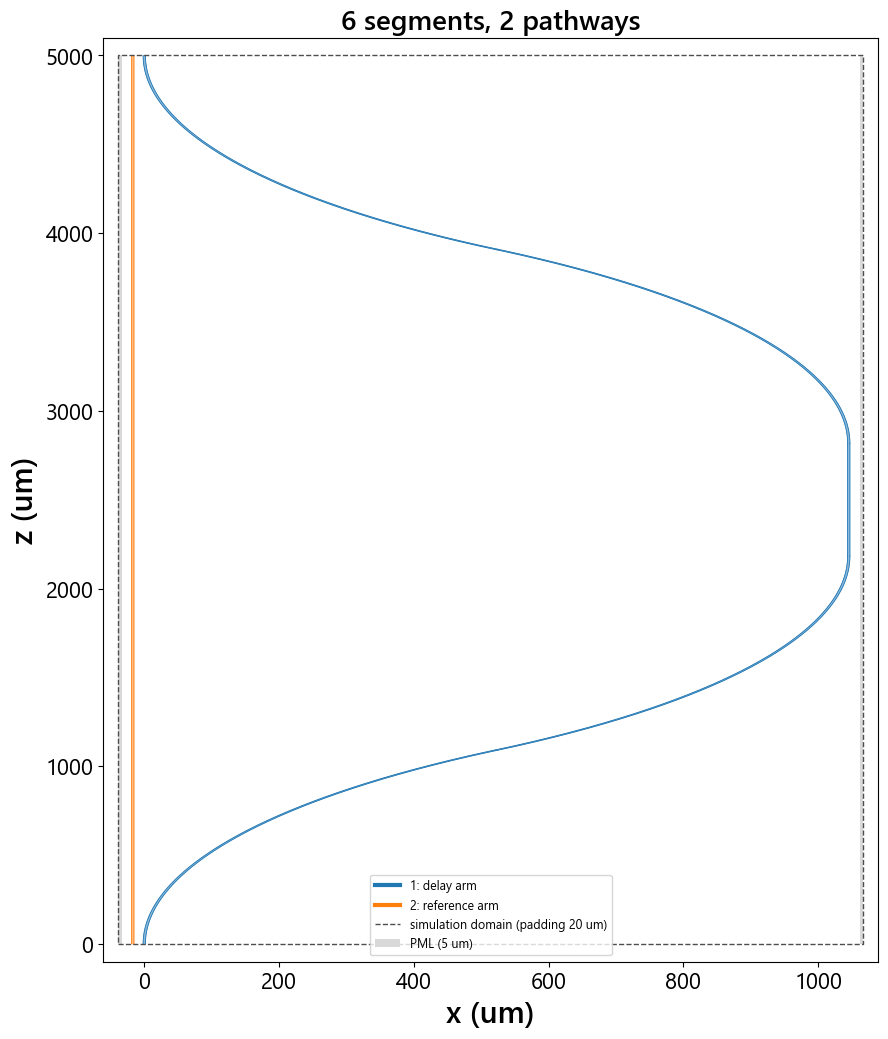

P-05c_UnbalancedMZI: delay arm - reference arm = 640.000000 μm (design 640 μm)
Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-05_UnbalancedMZI\P-05c_UnbalancedMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-05_UnbalancedMZI\P-05c_UnbalancedMZI.gds; 50000 propagation steps per wavelength


In [5]:
# Set up directories
device_name = 'P-05_UnbalancedMZI'
device_dir = f"D:\\DATA\\ETL_PIC\\simulation\\NullingPIC_Gen2_sims\\{device_name}\\"

# Set up parameters: (z length, path-length difference, bend radius) of each variant (um)
variants = {
    "P-05a_UnbalancedMZI": (8000.0, 160.0, 5000.0),
    "P-05b_UnbalancedMZI": (4000.0, 320.0, 1400.0),
    "P-05c_UnbalancedMZI": (5000.0, 640.0, 1400.0),
}
arm_pitch = 17.0                # reference arm, this far on the -x side of the delay arm (um)
pathway_labels = ["delay arm", "reference arm"]

circuits = {}
for variant_name, (z_length, deltaL, R) in variants.items():
    paths = device_paths(device_dir, variant_name)

    # Define the arms: the delay arm (S-bend out, straight, S-bend back) and a straight reference arm
    x, z, phi = rlib.delay_arm(z_length, deltaL, R, end_straight=0, x0=0.0, direction=1)
    xs = np.vstack([x, -arm_pitch * np.ones_like(x)])
    zs = np.vstack([z, z])
    phis = np.vstack([phi, np.zeros_like(phi)])

    # Define circuit: one pathway per arm, both launched; every segment extended
    c, info = rlib.paths_to_circuit(xs, zs, phis, width=WIDTH, orientation="extended")
    circuits[variant_name] = c

    # Export and visualize circuit
    export_device(c, paths)
    c.plot(labels=pathway_labels, figsize=(10, 12))      # after the export, so the plot shows the domain as written
    dL = c.path_length(c.pathways[0].segments) - c.path_length(c.pathways[1].segments)
    print(f"{variant_name}: delay arm - reference arm = {dL:.6f} μm (design {deltaL:g} μm)")
    print(f"Wrote {paths['ind']} and {paths['gds']}; {z_length / SIM['Step_z']:.0f} propagation steps per wavelength")

# Estimate interference pattern

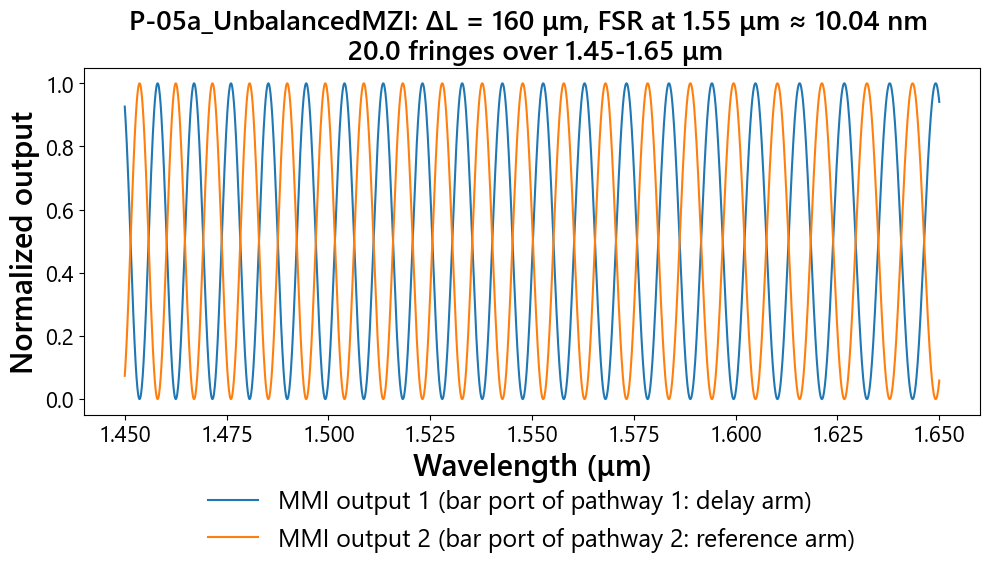

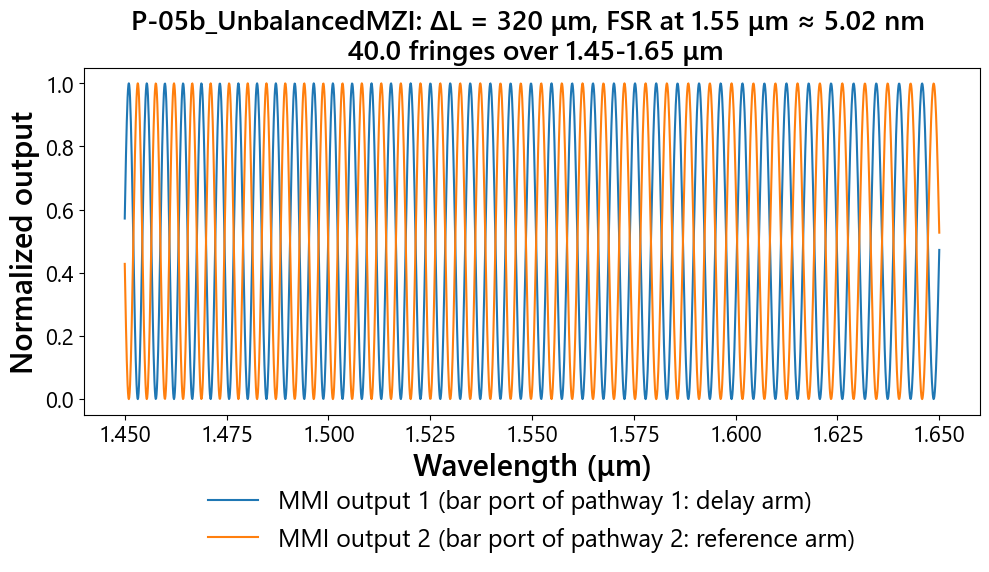

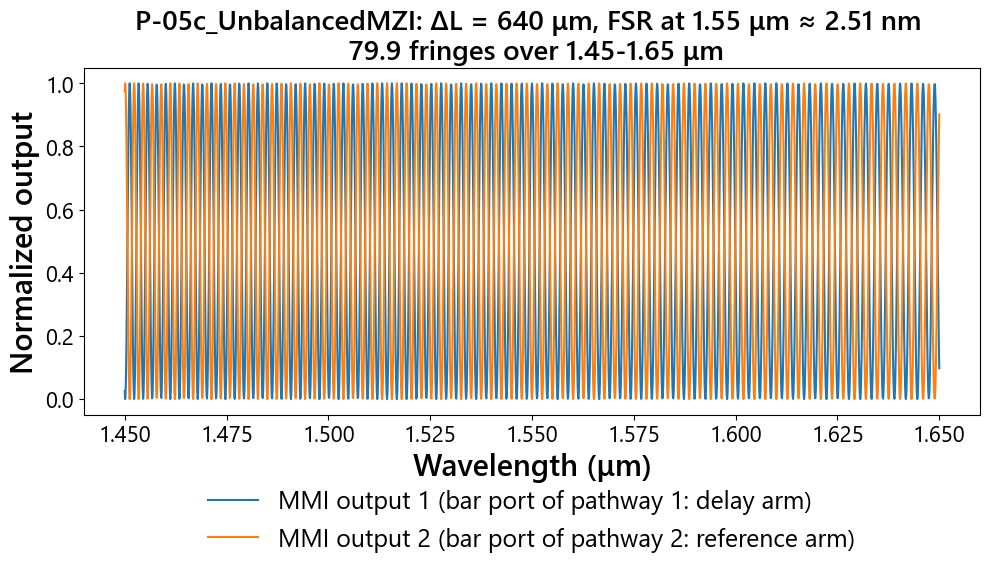

In [8]:
# Interference spectrum of each circuit: Y-splitter, the two pathways, 2x2 MMI
wl = np.linspace(1.45, 1.65, 2001)
tm = rlib.transfer

for variant_name, c in circuits.items():
    deltaL = variants[variant_name][1]
    est = rlib.estimate_pathways(c, wl)
    arm_a = tm.pathway(est, 1)                          # pathway 1: delay arm
    arm_b = tm.pathway(est, 2)                          # pathway 2: reference arm
    T = tm.mzi_response(wl, arm_a, arm_b, splitter="y", combiner="mmi")
    P = tm.power(T)                                     # (wavelengths, 2 outputs)
    dphi = est.difference(1, 2)["phase"]                # delay arm - reference arm
    n_fringes = abs(dphi[0] - dphi[-1]) / (2 * np.pi)
    fsr = tm.fsr(wl, dphi)

    plt.figure(figsize=(10, 6))
    plt.plot(wl, P[:, 0], label=f"MMI output 1 (bar port of pathway 1: {pathway_labels[0]})")
    plt.plot(wl, P[:, 1], label=f"MMI output 2 (bar port of pathway 2: {pathway_labels[1]})")
    plt.xlabel('Wavelength (μm)')
    plt.ylabel('Normalized output')
    plt.title(f"{variant_name}: ΔL = {deltaL:g} μm, FSR at 1.55 μm ≈ {np.interp(1.55, wl, fsr) * 1e3:.2f} nm \n "
              f"{n_fringes:.1f} fringes over {wl[0]:g}-{wl[-1]:g} μm")
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=1, frameon=False)
    plt.tight_layout()
    plt.show()